<a href="https://colab.research.google.com/github/ZPA2k/SocialMediaAnalysisCourseHW/blob/main/BasicVisualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Week 5
Use the same file as last week.


1.   Import seaborn and matplotlib in addition to pandas and numpy.
2.   Use the binary data from last week with the parents' level of education to check for a correlation with math, reading, and writing scores. Your correlation matrix should be a 4x4 matrix.
4. Pick a color scheme that you like and that we haven't used in class yet.
5. Create a scatterplot that shows the parents' level of education on the y axis and the math score on the x axis.
6. Why does this scatterplot not work as well as it might? Can you think of a better visualization to present this data?
7. Create dummy scores for the lunch data and check for a correlation with reading scores.



In [ ]:
#1
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
sns.set(color_codes=True)
import pandas as pd
import numpy as np

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/cvs files/Student Performance new.csv", index_col = 0)

In [ ]:
dfR = df.rename(columns={"race/ethnicity": "race","parental level of education":"paredu","test preparation course":"prep","math percentage": "math","reading score percentage":"reading","writing score percentage":"writing"})

In [ ]:
dfR["paredu_BDMD"] = dfR["paredu"].isin(["bachelor's degree","master's degree"]).astype(int)
dfR

,race,paredu,lunch,prep,math,reading,writing,sex,paredu_BDMD
0,group B,bachelor's degree,standard,none,0.72,0.72,0.74,F,1
1,group C,some college,standard,completed,0.69,0.90,0.88,F,0
2,group B,master's degree,standard,none,0.90,0.95,0.93,F,1
3,group A,associate's degree,free/reduced,none,0.47,0.57,0.44,M,0
4,group C,some college,standard,none,0.76,0.78,0.75,M,0
...,...,...,...,...,...,...,...,...,...
995,group E,master's degree,standard,completed,0.88,0.99,0.95,F,1
996,group C,high school,free/reduced,none,0.62,0.55,0.55,M,0
997,group C,high school,free/reduced,completed,0.59,0.71,0.65,F,0
998,group D,some college,standard,completed,0.68,0.78,0.77,F,0


In [ ]:
#2
matrix = dfR[["paredu_BDMD","math","reading","writing"]].corr()
matrix

,paredu_BDMD,math,reading,writing
paredu_BDMD,1.000000,0.104635,0.146883,0.186041
math,0.104635,1.000000,0.817580,0.802642
reading,0.146883,0.817580,1.000000,0.954598
writing,0.186041,0.802642,0.954598,1.000000


<Axes: >

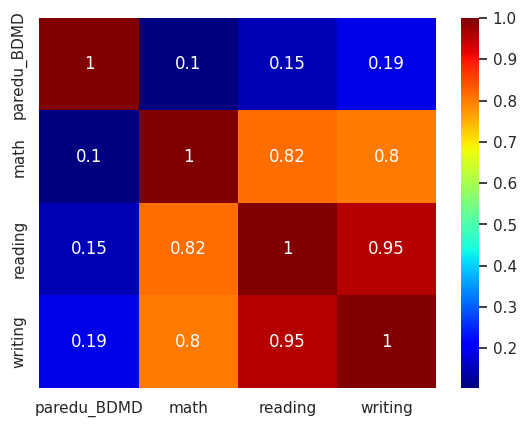

In [ ]:
#3
sns.heatmap(matrix,cmap="jet",annot=True)

<Axes: xlabel='math', ylabel='paredu'>

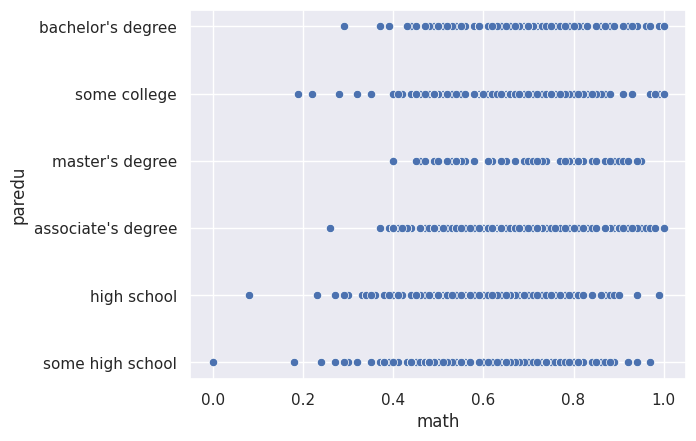

In [ ]:
#4
fig = plt.figure()
sp = fig.add_subplot()
sns.scatterplot(data=dfR, x= "math",y="paredu")

In [ ]:
#5 It is a bad visualization & cannot provide any critical meaning from the model.
#However, we can see which group tends to receive higher or lower scores by looking at how populated the points are and also vividly see the outliers.

<Axes: xlabel='math', ylabel='paredu'>

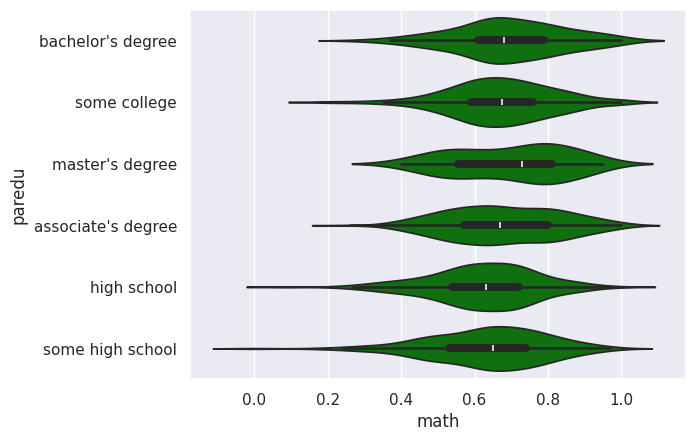

In [ ]:
fig1 = plt.figure()
sp1 = fig.add_subplot()
sns.violinplot(data=dfR, x= "math",y="paredu",color="green",)

In [ ]:
#6
lunch_dummy = pd.get_dummies(dfR["lunch"],drop_first=True)
dfR["lunch_dummy"] = lunch_dummy
dfR

,race,paredu,lunch,prep,math,reading,writing,sex,paredu_BDMD,lunch_dummy
0,group B,bachelor's degree,standard,none,0.72,0.72,0.74,F,1,True
1,group C,some college,standard,completed,0.69,0.90,0.88,F,0,True
2,group B,master's degree,standard,none,0.90,0.95,0.93,F,1,True
3,group A,associate's degree,free/reduced,none,0.47,0.57,0.44,M,0,False
4,group C,some college,standard,none,0.76,0.78,0.75,M,0,True
...,...,...,...,...,...,...,...,...,...,...
995,group E,master's degree,standard,completed,0.88,0.99,0.95,F,1,True
996,group C,high school,free/reduced,none,0.62,0.55,0.55,M,0,False
997,group C,high school,free/reduced,completed,0.59,0.71,0.65,F,0,False
998,group D,some college,standard,completed,0.68,0.78,0.77,F,0,True


,lunch_dummy,reading
lunch_dummy,1.00000,0.22956
reading,0.22956,1.00000


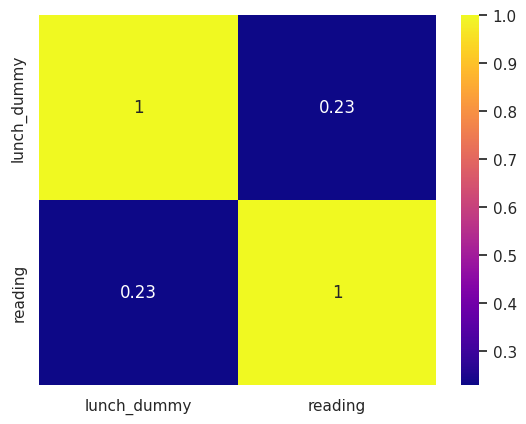

In [ ]:
lunch_read = dfR[["lunch_dummy","reading"]].corr()
sns.heatmap(lunch_read,cmap="plasma",annot=True)
lunch_read

In [ ]:
#Using the years of education for the parents might work too(more specifics)
#Using a Dummy variable will give a massive matrix
#5 be careful of the order of paredu and the labels


In [ ]:
#Data cleaning - check duplicates, drop unnecessary columns, check nulls, after that, check shape or head
#Missing data,
